In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [5]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio1_bcast.csv').sort_values('procesos')
df['mejora_x'] = df['t_secuencial_ms'] / df['t_arbol_ms']
df

,procesos,t_secuencial_ms,t_arbol_ms,mejora_x
0,2,14.3633,14.4448,0.994358
1,4,33.1334,18.9143,1.751765
2,8,66.6417,24.7789,2.689454
3,16,143.2179,37.9232,3.776525
4,32,309.2182,51.0687,6.054946


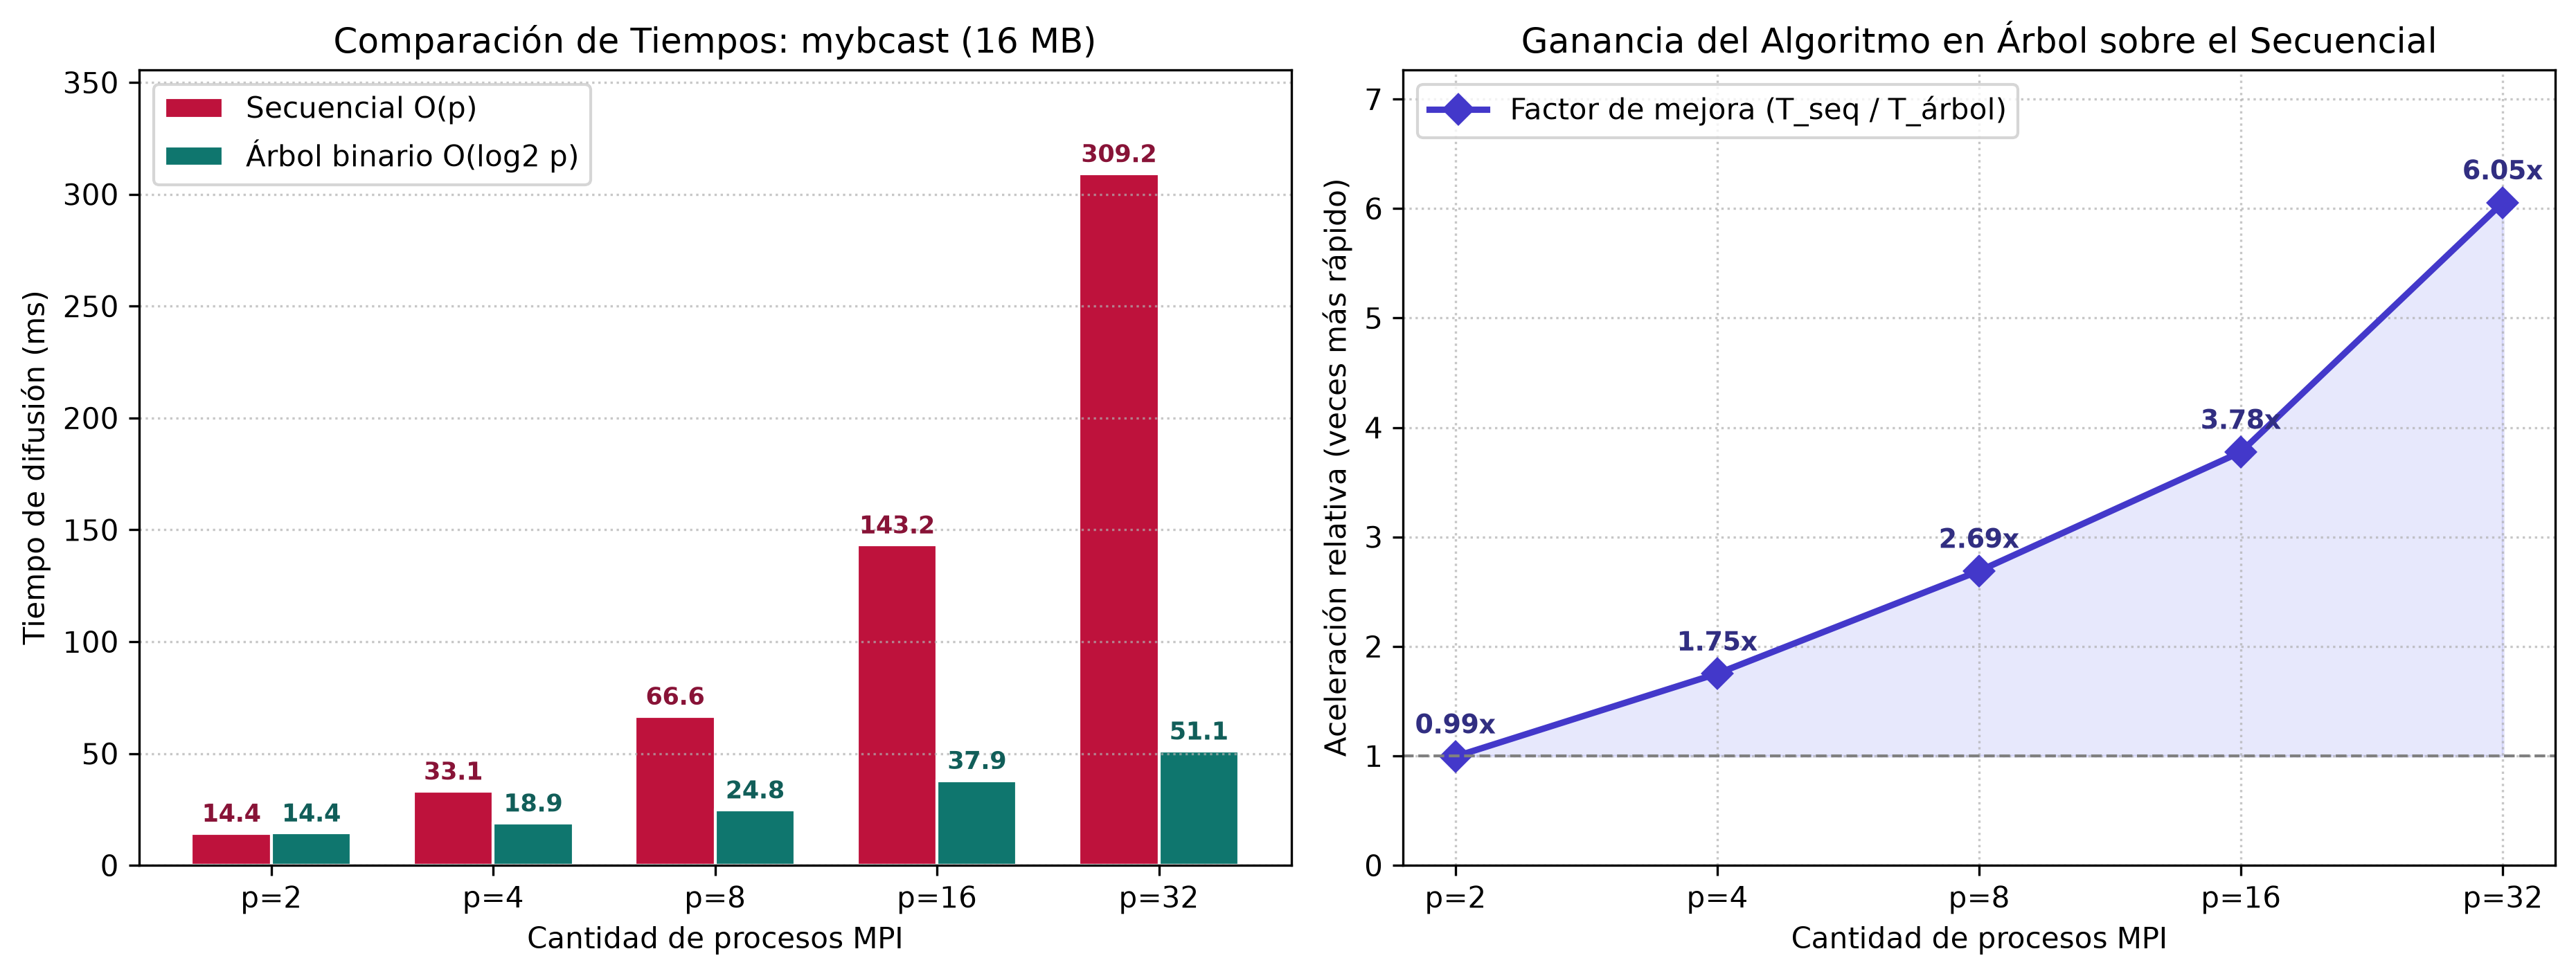

In [6]:
etiquetas = [f'p={p}' for p in df['procesos']]
x = np.arange(len(etiquetas))
ancho = 0.36

t_seq = df['t_secuencial_ms'].to_numpy()
t_arb = df['t_arbol_ms'].to_numpy()
mejora = df['mejora_x'].to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=300)

# Panel izquierdo: Barras agrupadas de tiempo en ms
b1 = ax1.bar(x - ancho / 2, t_seq, ancho, color='#be123c', edgecolor='white', label='Secuencial O(p)')
b2 = ax1.bar(x + ancho / 2, t_arb, ancho, color='#0f766e', edgecolor='white', label='Árbol binario O(log2 p)')

for bar in b1:
    h = bar.get_height()
    ax1.annotate(f'{h:.1f}', (bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8.5, color='#881337', fontweight='bold')
for bar in b2:
    h = bar.get_height()
    ax1.annotate(f'{h:.1f}', (bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8.5, color='#115e59', fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas)
ax1.set_ylim(0, max(t_seq) * 1.15)
ax1.set_xlabel('Cantidad de procesos MPI')
ax1.set_ylabel('Tiempo de difusión (ms)')
ax1.set_title('Comparación de Tiempos: mybcast (16 MB)')
ax1.legend()
ax1.grid(True, axis='y', linestyle=':', alpha=0.7)

# Panel derecho: Factor de aceleración del árbol respecto al secuencial
ax2.plot(x, mejora, marker='D', markersize=7, linewidth=2.2, color='#4338ca', label='Factor de mejora (T_seq / T_árbol)')
ax2.fill_between(x, 1.0, mejora, color='#6366f1', alpha=0.15)
ax2.axhline(1.0, linestyle='--', color='gray', linewidth=1)

for xi, yi in zip(x, mejora):
    ax2.annotate(f'{yi:.2f}x', (xi, yi), xytext=(0, 8), textcoords='offset points',
                 ha='center', fontsize=9, fontweight='bold', color='#312e81')

ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas)
ax2.set_ylim(0, max(mejora) * 1.2)
ax2.set_xlabel('Cantidad de procesos MPI')
ax2.set_ylabel('Aceleración relativa (veces más rápido)')
ax2.set_title('Ganancia del Algoritmo en Árbol sobre el Secuencial')
ax2.legend(loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e1_broadcast_tiempos.png', dpi=300)
plt.show()